# 06 — Evaluation
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 8**:
- Compute metrics **beyond R²**: **MAPE** and **MdAPE**
- Summarize insights, e.g. **which price bands** the model predicts better
- **Deliverable:** this notebook + `metrics_summary.csv`

I evaluate the three models from Week 7 (Linear Regression, Random Forest, and the tuned LightGBM) on the April 2026 test set, using the Week 6 features.

## Setup
LightGBM is needed again (already installed in Week 7).

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")      # hide version warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as before) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

## 1. What the metrics mean
So far I mostly used **R²** and **MAE**. This week I add percentage-based metrics:

| Metric | Formula (simple version) | What it tells me |
|---|---|---|
| **R²** | 1 − (squared errors ÷ variation in price) | how much of the price variation the model explains (1 = perfect) |
| **MAE** | average of \|predicted − actual\| | the average miss **in dollars** |
| **RMSE** | √(average of squared errors) | like MAE, but big misses count much more |
| **MAPE** | average of \|predicted − actual\| ÷ actual × 100 | the average miss **in percent** |
| **MdAPE** | **median** of \|predicted − actual\| ÷ actual × 100 | the **typical** miss in percent (half the homes are closer than this) |
| **Within 10% / 20%** | % of homes with error ≤ 10% / 20% | easy to explain to anyone |

**Why percent errors?** A \$100K miss is huge for a \$300K home but small for a \$5M home. Percent errors treat every home fairly, no matter its price.

**MAPE vs MdAPE:** MAPE is an average, so a few homes with very big percent errors pull it up. MdAPE is the median, so it isn't affected by those few homes.

In [2]:
def get_metrics(actual, pred):
    """All the metrics for one set of predictions (both in dollars)."""
    actual = np.array(actual)
    pred = np.array(pred)
    pct_error = np.abs(pred - actual) / actual * 100
    return {
        "R2": r2_score(actual, pred),
        "MAE ($)": mean_absolute_error(actual, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": pct_error.mean(),
        "MdAPE (%)": np.median(pct_error),
        "within 10% (%)": (pct_error <= 10).mean() * 100,
        "within 20% (%)": (pct_error <= 20).mean() * 100,
    }

# Quick check with a tiny example
print(get_metrics([100, 200, 400], [110, 180, 400]))

{'R2': 0.9892857142857143, 'MAE ($)': 10.0, 'RMSE ($)': np.float64(12.909944487358056), 'MAPE (%)': np.float64(6.666666666666667), 'MdAPE (%)': np.float64(10.0), 'within 10% (%)': np.float64(100.0), 'within 20% (%)': np.float64(100.0)}


## 2. Load the data and add the Week 6 features (same as Week 7)

In [3]:
train = pd.read_csv(os.path.join(path, "train_data.csv"))
test = pd.read_csv(os.path.join(path, "test_data.csv"))
print("Training rows:", len(train), "| months:", train["Month"].min(), "to", train["Month"].max())
print("Test rows:    ", len(test), "| month:", test["Month"].unique()[0])

# Bed/bath ratio and age
for d in [train, test]:
    d["BedBathRatio"] = d["BedroomsTotal"] / d["BathroomsTotalInteger"]
    d["AgeAtSale"] = d["Month"].str[:4].astype(int) - d["YearBuilt"]
    d.loc[d["AgeAtSale"] < 0, "AgeAtSale"] = 0

# School districts (High school districts last, so overlapping homes keep the more local district)
districts = gpd.read_file(os.path.join(path, "DistrictAreas2425.zip"))
districts["order"] = (districts["DistrictTy"] == "High").astype(int)
districts = districts.sort_values("order")

def add_district(df):
    points = gpd.GeoDataFrame(df[["Longitude", "Latitude"]].copy(),
                              geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
                              crs="EPSG:4326").to_crs(districts.crs)
    joined = gpd.sjoin(points, districts[["DistrictNa", "order", "geometry"]], how="left", predicate="within")
    joined = joined.sort_values("order").groupby(level=0).first()
    df = df.copy()
    df["District"] = joined["DistrictNa"].reindex(df.index)
    return df

train = add_district(train)
test = add_district(test)

# District price level, learned from train_part only
def add_district_level(train_part, other_part, k=20):
    train_part = train_part.copy()
    other_part = other_part.copy()
    log_ppsf = np.log(train_part["ClosePrice"] / train_part["LivingArea"])
    overall_median = log_ppsf.median()
    stats = log_ppsf.groupby(train_part["District"]).agg(["median", "count"])
    level = (stats["count"] * stats["median"] + k * overall_median) / (stats["count"] + k)
    for d in [train_part, other_part]:
        d["DistrictPriceLevel"] = d["District"].map(level).fillna(overall_median)
    return train_part, other_part

Training rows: 140798 | months: 2025-03 to 2026-03
Test rows:     12465 | month: 2026-04


In [4]:
number_cols = ["Latitude", "Longitude", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["Latitude", "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
new_cols = ["AgeAtSale", "BedBathRatio", "DistrictPriceLevel"]      # Week 6 features


def prepare(train, test, extra_cols=[]):
    """Same prepare() as Weeks 5-7."""
    train = train.copy()
    test = test.copy()
    num_cols = number_cols + extra_cols

    # 1. Missing values
    for col in flag_cols:
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in num_cols:
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = num_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # 4. Normalize with TRAINING mean and std
    for col in num_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test

## 3. Train the three models in two versions
Same as Week 7, I look at two versions of the data:
1. **Keep all homes**
2. **Drop the top and bottom 0.5% of prices** (cutoffs from the **training data**: \$195K to \$8.3M). This was my best version in Week 7.

LightGBM uses my **best Week 7 settings** (max_depth = 6, learning_rate = 0.05, n_estimators = 5,000). I don't tune again here, because tuning was already done on March 2026.

*This cell takes about 3–5 minutes (the Random Forest is the slowest).*

In [5]:
low = train["ClosePrice"].quantile(0.005)
high = train["ClosePrice"].quantile(0.995)
print(f"Price cutoffs from training data: ${low:,.0f} to ${high:,.0f}")

versions = {
    "All homes": (0, np.inf),
    "Drop top/bottom 0.5%": (low, high),
}

predictions = {}     # (version, model) -> predicted prices in dollars
test_sets = {}       # version -> the test homes used in that version

for version, (low_cut, high_cut) in versions.items():
    tr = train[(train["ClosePrice"] >= low_cut) & (train["ClosePrice"] <= high_cut)]
    te = test[(test["ClosePrice"] >= low_cut) & (test["ClosePrice"] <= high_cut)]
    tr_lvl, te_lvl = add_district_level(tr, te)
    X_tr, X_te, y_tr, y_te = prepare(tr_lvl, te_lvl, extra_cols=new_cols)
    test_sets[version] = te

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.3,
                                               n_jobs=-1, random_state=42),
        "LightGBM": lgb.LGBMRegressor(n_estimators=5000, learning_rate=0.05, max_depth=6, num_leaves=63,
                                      min_child_samples=20, subsample=0.8, subsample_freq=1,
                                      colsample_bytree=0.8, random_state=42, verbose=-1),
    }
    for name, model in models.items():
        start = time.time()
        model.fit(X_tr, y_tr)
        predictions[(version, name)] = np.exp(model.predict(X_te))   # back to dollars
        print(f"{version:22s} | {name:17s} | trained in {time.time() - start:5.1f} s")

Price cutoffs from training data: $195,000 to $8,300,450
All homes              | Linear Regression | trained in   3.3 s
All homes              | Random Forest     | trained in  22.7 s
All homes              | LightGBM          | trained in  30.9 s
Drop top/bottom 0.5%   | Linear Regression | trained in   3.6 s
Drop top/bottom 0.5%   | Random Forest     | trained in  22.8 s
Drop top/bottom 0.5%   | LightGBM          | trained in  18.1 s


## 4. All the metrics for every model

In [6]:
rows = []
for (version, name), pred in predictions.items():
    actual = test_sets[version]["ClosePrice"]
    row = {"version": version, "model": name, "test homes": len(actual)}
    row.update(get_metrics(actual, pred))
    rows.append(row)

metrics = pd.DataFrame(rows)
metrics

,version,model,test homes,R2,MAE ($),RMSE ($),MAPE (%),MdAPE (%),within 10% (%),within 20% (%)
0,All homes,Linear Regression,12465,0.7437,"252,323.8611","725,108.6021",16.8169,11.6078,44.5969,72.3065
1,All homes,Random Forest,12465,0.7644,"203,461.8530","695,180.1862",12.9580,8.2960,56.6466,81.4280
2,All homes,LightGBM,12465,0.8028,"182,516.4328","636,079.5705",11.8165,7.8315,59.2379,84.3081
3,Drop top/bottom 0.5%,Linear Regression,12338,0.8041,"219,051.7339","434,132.1801",16.1699,11.3162,45.3315,73.2372
4,Drop top/bottom 0.5%,Random Forest,12338,0.8599,"174,708.1805","367,096.7019",12.4843,8.1431,57.4161,82.1689
5,Drop top/bottom 0.5%,LightGBM,12338,0.8975,"154,994.1985","313,983.8218",11.2549,7.7715,60.0178,85.1516


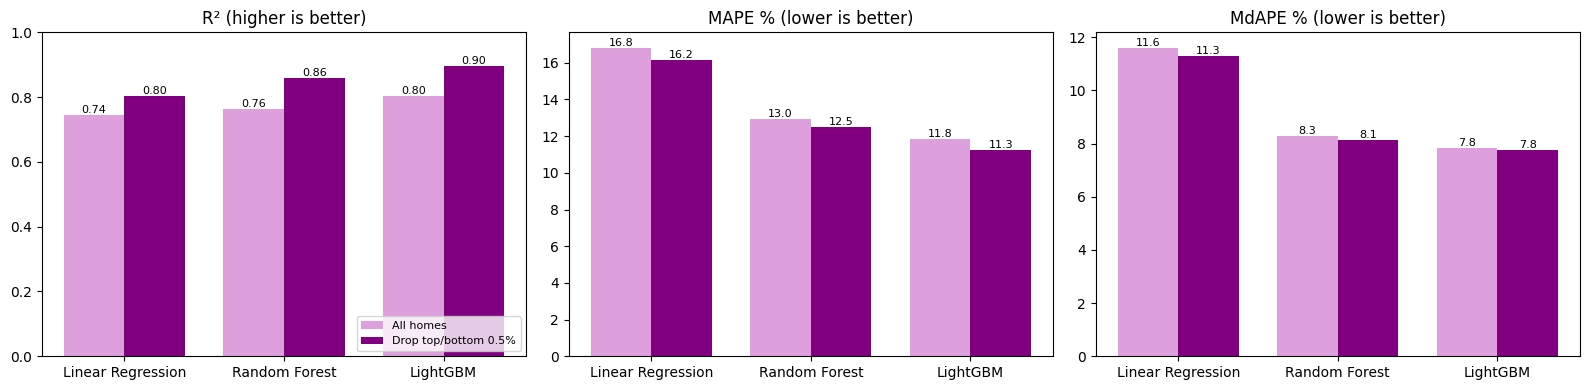

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
model_names = ["Linear Regression", "Random Forest", "LightGBM"]
x = np.arange(len(model_names))
width = 0.38

for ax, col, title in zip(axes, ["R2", "MAPE (%)", "MdAPE (%)"],
                          ["R² (higher is better)", "MAPE % (lower is better)", "MdAPE % (lower is better)"]):
    for i, (version, color) in enumerate([("All homes", "plum"), ("Drop top/bottom 0.5%", "purple")]):
        values = metrics[metrics["version"] == version].set_index("model").loc[model_names, col]
        bars = ax.bar(x + (i - 0.5) * width, values, width, label=version, color=color)
        for b, v in zip(bars, values):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}" if col == "R2" else f"{v:.1f}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names)
    ax.set_title(title)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**What I notice:**
- **LightGBM is the best on every metric**, in both versions. With the top/bottom 0.5% dropped: **R² = 0.898, MAPE = 11.3%, MdAPE = 7.8%**, and **85%** of homes are within 20% of the real price.
- **MAPE is always higher than MdAPE** (11.3% vs 7.8% for LightGBM). The average is pulled up by a small number of homes with very big percent errors, while the typical home is predicted within about 8%.
- Dropping the extreme prices changes **R² a lot** (0.80 → 0.90) but **MAPE and MdAPE barely move** (MdAPE stays at about 7.8%). R² in dollars is very sensitive to a few expensive homes; percent errors aren't.
- Linear Regression has a much higher MdAPE (11.3%) than the tree models (~8%), so the tree models are better for typical homes too, not just the expensive ones.

## 5. Which price bands does the model predict better?
From here on I use my **final model: LightGBM, with the top/bottom 0.5% dropped** (best version from Week 7).

I split the April test homes into **price bands** by their **actual** sale price and compute the metrics for each band. I also add the **median signed error**: if it's negative, the model usually guesses **too low** for that band; if positive, **too high**.

In [8]:
final = test_sets["Drop top/bottom 0.5%"][["ClosePrice", "CountyOrParish", "LivingArea", "AgeAtSale"]].copy()
final["predicted"] = predictions[("Drop top/bottom 0.5%", "LightGBM")]
final["pct_error"] = (final["predicted"] - final["ClosePrice"]) / final["ClosePrice"] * 100   # signed

band_edges = [0, 500_000, 750_000, 1_000_000, 1_500_000, 2_000_000, 3_000_000, np.inf]
band_names = ["under $500K", "$500K-750K", "$750K-1M", "$1M-1.5M", "$1.5M-2M", "$2M-3M", "$3M+"]
final["price band"] = pd.cut(final["ClosePrice"], bins=band_edges, labels=band_names, right=False)


def group_metrics(df, group_col):
    rows = []
    for group, part in df.groupby(group_col, observed=True):
        row = {group_col: group, "homes": len(part), "% of homes": len(part) / len(df) * 100}
        row.update(get_metrics(part["ClosePrice"], part["predicted"]))
        row["median signed error (%)"] = part["pct_error"].median()
        rows.append(row)
    return pd.DataFrame(rows).set_index(group_col)


bands = group_metrics(final, "price band")
bands[["homes", "% of homes", "MAE ($)", "MAPE (%)", "MdAPE (%)", "within 10% (%)", "median signed error (%)"]]

,homes,% of homes,MAE ($),MAPE (%),MdAPE (%),within 10% (%),median signed error (%)
price band,,,,,,,
under $500K,1687,13.6732,"50,155.5159",13.7709,7.4845,59.2768,2.0921
$500K-750K,2661,21.5675,"56,426.5765",9.0613,6.0299,70.7253,-0.7552
$750K-1M,2499,20.2545,"76,091.3708",8.8154,6.4588,70.3481,-0.9558
$1M-1.5M,2450,19.8574,"133,977.8912",10.9368,8.3840,56.9796,-2.4612
$1.5M-2M,1344,10.8932,"217,223.8362",12.6192,9.8240,50.4464,-4.3898
$2M-3M,975,7.9024,"337,986.7904",13.8987,11.3015,44.6154,-7.0811
$3M+,722,5.8518,"744,696.4270",16.8738,13.9127,35.4571,-10.4759


*R² isn't very useful inside one price band, because all homes in a band have similar prices (there's little variation left to explain). That's another reason percent errors are better for this comparison.*

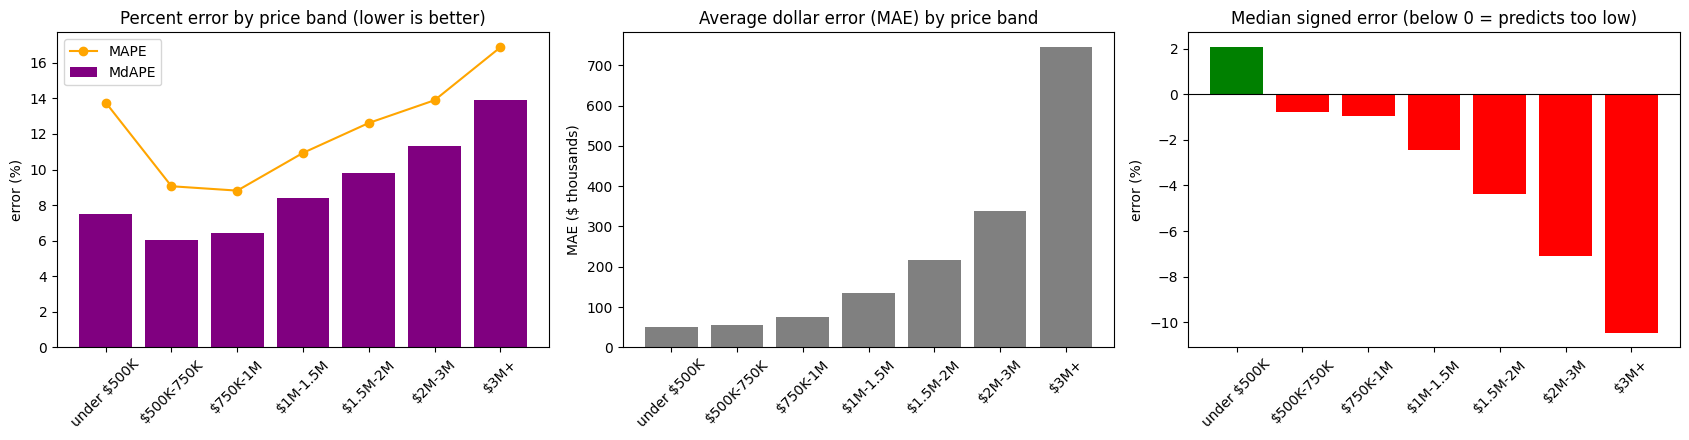

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].bar(bands.index.astype(str), bands["MdAPE (%)"], color="purple", label="MdAPE")
axes[0].plot(bands.index.astype(str), bands["MAPE (%)"], color="orange", marker="o", label="MAPE")
axes[0].set_title("Percent error by price band (lower is better)")
axes[0].set_ylabel("error (%)")
axes[0].legend()

axes[1].bar(bands.index.astype(str), bands["MAE ($)"] / 1000, color="gray")
axes[1].set_title("Average dollar error (MAE) by price band")
axes[1].set_ylabel("MAE ($ thousands)")

colors = ["red" if v < 0 else "green" for v in bands["median signed error (%)"]]
axes[2].bar(bands.index.astype(str), bands["median signed error (%)"], color=colors)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_title("Median signed error (below 0 = predicts too low)")
axes[2].set_ylabel("error (%)")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**What I notice:**
- **The model is best for \$500K – \$1M homes**: MdAPE about **6%**, and about **70%** of these homes are predicted within 10%. These are also the most common homes (about 42% of April sales), so the model has the most examples to learn from.
- **The error grows steadily for more expensive homes**: MdAPE goes from 8.4% (\$1M–1.5M) up to **13.9% for \$3M+**. Expensive homes vary more (views, finishes, lot quality) in ways my features can't see, and there are fewer of them to learn from.
- **Expensive homes are predicted too low**: the median signed error is about **−10% for \$3M+**. The model pulls predictions toward the middle, so it underestimates the top of the market.
- **Homes under \$500K** have a low MdAPE (7.5%) but a high MAPE (13.8%). Most cheap homes are predicted well, but a few are **predicted far too high** (signed error +2%). These could be fixer-uppers or special sales the model can't know about.
- In **dollars**, the MAE for \$3M+ homes is about **\$745K**, versus about \$50K for homes under \$500K. That's why R² in dollars is driven by the expensive homes.

## 6. Which counties does the model predict better?
I only show counties with at least **100 test homes**, so the numbers aren't based on just a few sales.

In [10]:
counties = group_metrics(final, "CountyOrParish")
counties = counties[counties["homes"] >= 100].sort_values("MdAPE (%)")
counties[["homes", "MAE ($)", "MAPE (%)", "MdAPE (%)", "within 10% (%)", "median signed error (%)"]]

,homes,MAE ($),MAPE (%),MdAPE (%),within 10% (%),median signed error (%)
CountyOrParish,,,,,,
Riverside,1883,"93,581.3676",9.6184,6.4007,68.0828,-1.4190
San Bernardino,1237,"57,818.4603",9.7201,6.4654,67.1787,-1.1904
Kern,141,"51,605.8818",11.9198,7.3475,62.4113,-1.8577
Orange,1175,"187,232.5946",9.7118,7.4071,62.2979,-2.6282
Butte,145,"45,876.9667",9.4559,7.6473,62.0690,0.5786
Contra Costa,584,"131,902.2038",10.4372,7.7987,60.2740,-1.9054
Los Angeles,3017,"179,379.4167",11.5816,8.0977,57.5406,-1.2797
San Diego,1451,"186,148.0926",11.7152,8.1073,58.3735,-2.2312
Ventura,419,"167,645.2828",11.3733,8.3287,59.4272,-2.2497


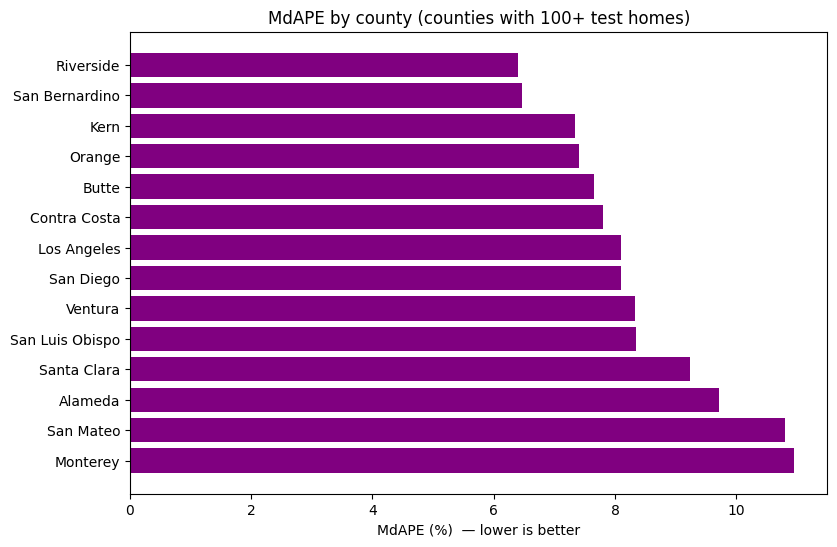

In [11]:
plt.figure(figsize=(9, 6))
plt.barh(counties.index[::-1], counties["MdAPE (%)"][::-1], color="purple")
plt.title("MdAPE by county (counties with 100+ test homes)")
plt.xlabel("MdAPE (%)  — lower is better")
plt.show()

**What I notice:**
- The model is most accurate in the **Inland Empire**: **Riverside (6.4%)** and **San Bernardino (6.5%)**. Homes there are more similar to each other (many newer tract homes).
- It's least accurate in the expensive **Bay Area and coastal counties**: **Monterey (11.0%)**, **San Mateo (10.8%)**, and **Alameda (9.7%)**.
- In **every county except Butte**, the median signed error is negative, so the model slightly **under-predicts**. It's strongest in expensive counties (about −3% to −4%). This matches the price band result.
- Los Angeles has the most test homes (3,017) and lands in the middle (8.1%).

## 7. Home size and age
Two more quick checks: does the error change with **home size** (living area) or **home age**?

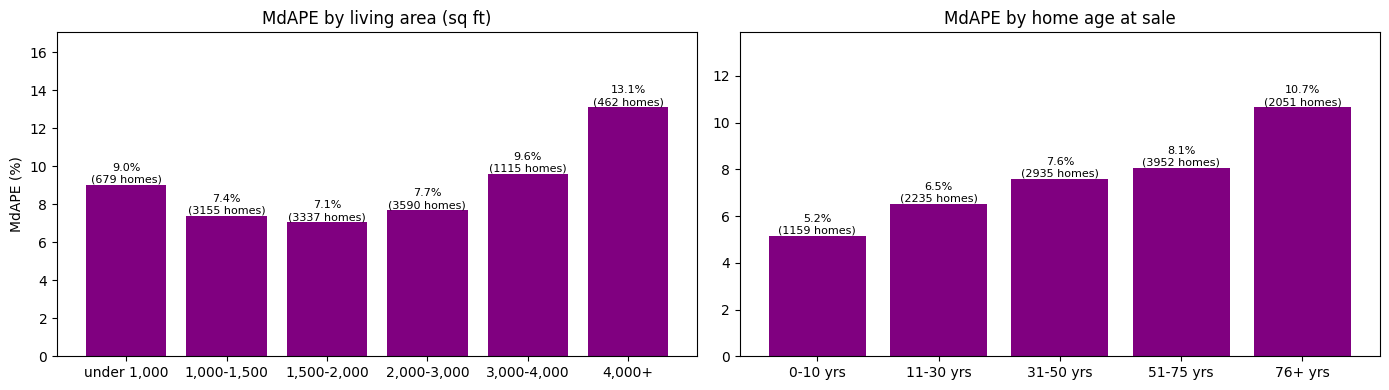

homes  MdAPE (%)  MAPE (%)
size under 1,000    679     9.0377   13.3307
     1,000-1,500   3155     7.3895   10.2343
     1,500-2,000   3337     7.0647   10.4141
     2,000-3,000   3590     7.6989   10.9774
     3,000-4,000   1115     9.6164   13.7444
     4,000+         462    13.1200   17.3938
age  0-10 yrs      1159     5.1671    8.7015
     11-30 yrs     2235     6.5337    9.7503
     31-50 yrs     2935     7.6075   10.7768
     51-75 yrs     3952     8.0677   11.3666
     76+ yrs       2051    10.6674   14.7915

In [12]:
final["size band"] = pd.cut(final["LivingArea"], bins=[0, 1000, 1500, 2000, 3000, 4000, np.inf],
                            labels=["under 1,000", "1,000-1,500", "1,500-2,000", "2,000-3,000", "3,000-4,000", "4,000+"],
                            right=False)
final["age band"] = pd.cut(final["AgeAtSale"], bins=[-1, 10, 30, 50, 75, np.inf],
                           labels=["0-10 yrs", "11-30 yrs", "31-50 yrs", "51-75 yrs", "76+ yrs"])

sizes = group_metrics(final, "size band")
ages = group_metrics(final, "age band")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(sizes.index.astype(str), sizes["MdAPE (%)"], color="purple")
axes[0].set_title("MdAPE by living area (sq ft)")
axes[0].set_ylabel("MdAPE (%)")
axes[1].bar(ages.index.astype(str), ages["MdAPE (%)"], color="purple")
axes[1].set_title("MdAPE by home age at sale")
for ax, table in zip(axes, [sizes, ages]):
    for i, (v, n) in enumerate(zip(table["MdAPE (%)"], table["homes"])):
        ax.text(i, v, f"{v:.1f}%\n({n} homes)", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, table["MdAPE (%)"].max() * 1.3)
plt.tight_layout()
plt.show()

pd.concat([sizes[["homes", "MdAPE (%)", "MAPE (%)"]], ages[["homes", "MdAPE (%)", "MAPE (%)"]]],
          keys=["size", "age"])

**What I notice:**
- **Size:** homes between **1,000 and 3,000 sq ft** are predicted best (MdAPE about **7–7.7%**). Very small homes (under 1,000 sq ft, 9.0%) and very large ones (4,000+ sq ft, **13.1%**) are harder, because they're less common.
- **Age:** the error goes up steadily with age, from **5.2% for homes 0–10 years old** to **10.7% for homes over 75 years old**. Newer homes are more alike. Older homes may be remodeled or run-down, and my data doesn't show their condition.

## 8. The biggest misses
Which homes have the largest percent errors? Looking at the 10 worst helps explain why MAPE is higher than MdAPE.

In [13]:
worst = final.reindex(final["pct_error"].abs().sort_values(ascending=False).index).head(10)
worst[["ClosePrice", "predicted", "pct_error", "CountyOrParish", "LivingArea", "price band"]].round(0)

,ClosePrice,predicted,pct_error,CountyOrParish,LivingArea,price band
4560,"355,000.0000","1,523,664.0000",329.0000,Santa Clara,"1,248.0000",under $500K
12265,"1,184,000.0000","3,782,707.0000",219.0000,San Diego,"3,116.0000",$1M-1.5M
6795,"240,000.0000","744,587.0000",210.0000,San Diego,"1,680.0000",under $500K
10568,"400,000.0000","1,231,838.0000",208.0000,Los Angeles,"2,537.0000",under $500K
11451,"1,400,000.0000","4,204,424.0000",200.0000,Los Angeles,"4,790.0000",$1M-1.5M
7417,"470,000.0000","1,396,903.0000",197.0000,San Diego,"3,040.0000",under $500K
9015,"224,000.0000","649,033.0000",190.0000,San Bernardino,"4,454.0000",under $500K
7488,"300,000.0000","833,588.0000",178.0000,Ventura,"1,689.0000",under $500K
6638,"268,000.0000","734,273.0000",174.0000,Siskiyou,"2,140.0000",under $500K
6220,"457,000.0000","1,226,379.0000",168.0000,San Diego,"1,680.0000",under $500K


In [14]:
over_50 = (final["pct_error"].abs() > 50).mean() * 100
print(f"Homes with an error over 50%: {over_50:.1f} %")

mape_all = final["pct_error"].abs().mean()
mape_without = final.loc[final["pct_error"].abs() <= 50, "pct_error"].abs().mean()
print(f"MAPE with all homes:                {mape_all:.2f} %")
print(f"MAPE without the >50% misses:       {mape_without:.2f} %")
print(f"MdAPE (not affected by the misses): {final['pct_error'].abs().median():.2f} %")

Homes with an error over 50%: 1.6 %
MAPE with all homes:                11.25 %
MAPE without the >50% misses:       10.19 %
MdAPE (not affected by the misses): 7.77 %


**What I notice:**
- The 10 biggest misses are all **over-predictions of about 170–330%**. Most of them are homes that sold for **under \$500K** while the model expected \$650K – \$1.5M.
- These are probably **not normal sales**: for example a fixer-upper, a sale between family members, or a home with a problem. My features (size, location, age, etc.) can't see any of that.
- Only **1.6%** of homes have an error over 50%. Removing them lowers MAPE from **11.3% to 10.2%**, while MdAPE stays at **7.8%**. This shows why **MdAPE is the better "typical error" number**: it isn't pulled up by a few unusual sales.

## 9. Save `metrics_summary.csv` (Week 8 deliverable)
I save the overall metrics for every model and version, plus the price-band table for the final model.

In [15]:
summary = metrics.round(4)
summary.to_csv(os.path.join(path, "metrics_summary.csv"), index=False)

bands.round(4).to_csv(os.path.join(path, "price_band_metrics.csv"))
print("Saved metrics_summary.csv and price_band_metrics.csv")
summary

Saved metrics_summary.csv and price_band_metrics.csv


,version,model,test homes,R2,MAE ($),RMSE ($),MAPE (%),MdAPE (%),within 10% (%),within 20% (%)
0,All homes,Linear Regression,12465,0.7437,"252,323.8611","725,108.6021",16.8169,11.6078,44.5969,72.3065
1,All homes,Random Forest,12465,0.7644,"203,461.8530","695,180.1862",12.9580,8.2960,56.6466,81.4280
2,All homes,LightGBM,12465,0.8028,"182,516.4328","636,079.5705",11.8165,7.8315,59.2379,84.3081
3,Drop top/bottom 0.5%,Linear Regression,12338,0.8041,"219,051.7339","434,132.1801",16.1699,11.3162,45.3315,73.2372
4,Drop top/bottom 0.5%,Random Forest,12338,0.8599,"174,708.1805","367,096.7019",12.4843,8.1431,57.4161,82.1689
5,Drop top/bottom 0.5%,LightGBM,12338,0.8975,"154,994.1985","313,983.8218",11.2549,7.7715,60.0178,85.1516


## Summary (Week 8)
**Overall metrics (April 2026 test set, top/bottom 0.5% of prices dropped):**

| Model | R² | MAE | MAPE | MdAPE | Within 10% | Within 20% |
|---|---|---|---|---|---|---|
| Linear Regression | 0.804 | \$219K | 16.2% | 11.3% | 45% | 73% |
| Random Forest | 0.860 | \$175K | 12.5% | 8.1% | 57% | 82% |
| **LightGBM** | **0.898** | **\$155K** | **11.3%** | **7.8%** | **60%** | **85%** |

**Key insights:**
1. **LightGBM is the best model on every metric.** The typical home (MdAPE) is predicted within about **7.8%** of its real price.
2. **MAPE > MdAPE** because a small number of unusual sales (1.6% of homes have errors over 50%) pull the average up. **MdAPE is the better "typical error".**
3. **Price bands:** the model is best for **\$500K – \$1M homes (about 6% MdAPE)** and worst for **\$3M+ homes (about 14%)**, which it also **under-predicts by about 10%**.
4. **Location:** most accurate in **Riverside and San Bernardino (~6.5%)**, least accurate in **Monterey, San Mateo and Alameda (10–11%)**.
5. **Home type:** mid-sized (1,000 – 3,000 sq ft) and newer homes are easiest to predict. Very large and very old homes are hardest.

**Files saved:** `metrics_summary.csv` (all metrics, every model and version) and `price_band_metrics.csv` (metrics by price band for LightGBM).

**Next step:** the biggest room for improvement is **expensive and older homes**. Features about home condition or view quality (if available) could help most there.